# Run F.E. Walter in Jupyter

From a clone of HydroReOpLLM, install the package and JupyterLab with the commands in the [tutorial guide](README.md). Open this notebook with the Python environment where you installed the package.

Choose **Run All** to simulate the first seven days of 2021 with the Rule-based baseline, verify the saved run, and see its daily releases and storage. The last section lets you run the two LLM cases with local Ollama when you are ready.

In [ ]:
from pathlib import Path
from shutil import copytree
from tempfile import mkdtemp

import matplotlib.pyplot as plt
import pandas as pd
import yaml

from llm_reservoir_agent.verification import verify_run
from llm_reservoir_agent.workflow import load_settings, run_settings

root = Path.cwd()
if root.name == "tutorials":
    root = root.parent
example_dir = root / "examples" / "fe_walter"
if not (example_dir / "rule_based.yaml").is_file():
    raise FileNotFoundError("Open the notebook from the HydroReOpLLM checkout or its tutorials directory.")

config_paths = {
    "Rule-based": example_dir / "rule_based.yaml",
    "Without operational knowledge": example_dir / "seasonal_target.yaml",
    "With operational knowledge": example_dir / "dkp.yaml",
}


def run_case(name, *, allow_network=False):
    run_root = Path(mkdtemp(prefix="hydroreopllm-walter-"))
    case_copy = run_root / "examples" / "fe_walter"
    copytree(example_dir, case_copy)
    settings = load_settings(case_copy / config_paths[name].name)
    output = Path(settings.report["output"])
    print(f"{name} outputs: {output}")
    run_settings(settings, allow_network=allow_network)
    verification = verify_run(output, require_offline=not allow_network)
    trajectory = pd.read_csv(output / "reservoir_trajectory.csv", parse_dates=["date"])
    return {"trajectory": trajectory, "verification": verification, "output": output}

## 1. Run the Rule-based baseline

The Hanasaki rule uses the shared F.E. Walter inflow and reservoir settings. Each execution saves the verified output in a new local temporary directory, whose path appears below.

In [2]:
baseline = run_case("Rule-based")
proof = baseline["verification"]
print(f"Verification {proof['status']} | {proof['days']} days | {proof['observed_network_calls']} network calls")
print(f"Maximum water balance residual: {proof['max_system_balance_residual_m3']:.3g} m³")

columns = {
    "date": "Date",
    "inflow_cms": "Inflow (m³/s)",
    "controlled_release_cms": "Controlled release (m³/s)",
    "spill_cms": "Spill (m³/s)",
    "storage_end_m3": "End storage (m³)",
}
daily_table = baseline["trajectory"][list(columns)].copy()
daily_table["date"] = daily_table["date"].dt.strftime("%Y-%m-%d")
daily_table.round(2).rename(columns=columns)


Verification PASS | 7 days | 0 network calls
Maximum water balance residual: 9.31e-10 m³


,Date,Inflow (m³/s),Controlled release (m³/s),Spill (m³/s),End storage (m³)
0,2021-01-01,10.67,8.46,0.0,4528362.50
1,2021-01-02,8.77,6.98,0.0,4683032.79
2,2021-01-03,7.82,6.24,0.0,4819532.43
3,2021-01-04,7.33,5.86,0.0,4946693.47
4,2021-01-05,7.07,5.66,0.0,5068793.68
5,2021-01-06,6.91,5.53,0.0,5187900.96
6,2021-01-07,6.81,5.45,0.0,5305015.67


## 2. Read the results

Compare inflow and controlled release in the upper panel. Then check the storage line below. Over each day, storage rises when inflow exceeds controlled release plus spill and falls when it is lower. The table lists spill separately. Use the verified water balance to check the accounting before interpreting the policy.

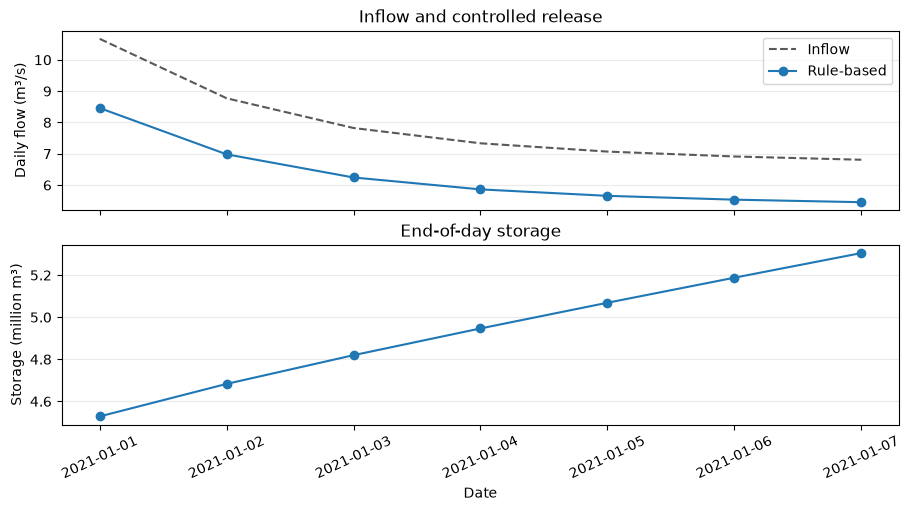

In [3]:
def plot_results(runs):
    figure, (flow_axis, storage_axis) = plt.subplots(2, 1, sharex=True, figsize=(9, 5), layout="constrained")
    inflow = runs["Rule-based"]["trajectory"]
    flow_axis.plot(inflow["date"], inflow["inflow_cms"], color="0.35", linestyle="--", label="Inflow")
    for name, run in runs.items():
        daily = run["trajectory"]
        flow_axis.plot(daily["date"], daily["controlled_release_cms"], marker="o", label=name)
        storage_axis.plot(daily["date"], daily["storage_end_m3"] / 1_000_000, marker="o", label=name)
    flow_axis.set(ylabel="Daily flow (m³/s)", title="Inflow and controlled release")
    storage_axis.set(ylabel="Storage (million m³)", xlabel="Date", title="End-of-day storage")
    flow_axis.legend()
    for axis in (flow_axis, storage_axis):
        axis.grid(axis="y", alpha=0.25)
    storage_axis.tick_params(axis="x", labelrotation=25)
    return figure


baseline_figure = plot_results({"Rule-based": baseline})
plt.show()

## 3. See what changes between the LLM cases

Both cases use the same seven study dates, reservoir, inflow, seasonal targets, and model profile. **With operational knowledge** also loads the local operating guidance. The table lists each prompt file and the planned number of decisions. The check reads the setup offline without making model requests.

In [ ]:
check_results = {name: load_settings(path).report for name, path in config_paths.items()}
comparison = {}
for name in ("Without operational knowledge", "With operational knowledge"):
    config = yaml.safe_load(config_paths[name].read_text(encoding="utf-8"))
    operator = config["agents"]["walter_operator"]
    comparison[name] = {
        "System prompt": operator["prompt"]["system"],
        "Daily prompt": operator["prompt"]["user"],
        "Operating guidance": ", ".join(operator.get("knowledge", {}).values()),
        "Planned decisions": check_results[name]["planned_llm_calls"],
    }

pd.DataFrame.from_dict(comparison, orient="index")

## 4. Optionally compare the two LLM runs

Start local Ollama with `gemma4:12b`. Set `RUN_LLM` to `True` and run the next two cells. The two YAMLs point to the local Ollama endpoint and allow up to 14 requests per case, including retries. Restore `False` before using Run All for an offline run.

If you run both cases, compare their release and storage lines against the shared inflow and the Rule-based baseline. These seven-day runs use the public prompts and simulator. Use the [results guide](../docs/RESULTS_GUIDE.md) to inspect the verified output, daily decisions, and provider attempts.

In [ ]:
RUN_LLM = False

In [ ]:
llm_runs = {}
if RUN_LLM:
    for name in comparison:
        llm_runs[name] = run_case(name, allow_network=True)
        verification = llm_runs[name]["verification"]
        print(f"Verification {verification['status']} | {verification['days']} days | {verification['observed_network_calls']} network calls")
    comparison_figure = plot_results({"Rule-based": baseline, **llm_runs})
    plt.show()
else:
    print("Run All completed the offline baseline. Enable RUN_LLM above to compare the two Ollama runs.")